멀티 에이전트
- 에이전트에 노드를 추가하지 않고 따로 필요한 이유?
- 예) 사용할 수 있는 검색 엔진이 다수. 이를 별도의 에이전트에 담아 전문가 집단을 만드는 식

노드와 에이전트의 차이
- 노드: 그래프 안에서 실행 단위 하나. llm 포함할 수도 없이 함수일 수도.
- 에이전트: 목표를 가지고 실행 할 수 있는 시스템. 노드를 포함할 수 있는 전체적인 지능 시스템. 판단을 위해 무조건 llm이 필요

# **1. 멀티 에이전트**
- 단일 Agent가 조사, 분석, 작성, 검수까지 모두 맡으면 프롬프트가 복잡해지고, 실패 지점이나 책임을 구분하기 어려움
- 멀티 에이전트는 작업을 역할별로 나누고, 각 결과를 다음 담당자에게 전달
    - Network: 동료 간 상호 위임이 가능한 연결 구조
    - Supervisor: 여러 담당자의 순서를 결정하는 중앙 관리자
    - Hierarchical: 팀 안에 팀이 있는 계층적 조직

### HandOff
- 현재 담당자가 다른 담당자에게 실행 제어권을 넘기는 것

In [9]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from langgraph.types import Command

In [3]:
class HandOffState(TypedDict, total=False):
    request: str
    department: str
    answer: str

def triage(state: HandOffState):
    text = state["request"].lower()
    dept = 'coding' if any(k in text for k in ('파이썬','코드','python','for문')) else 'writing'
    return {'department':dept}

def coding(state: HandOffState):
    return {"answer":f"[코딩담당]{state['request']} > 예제: for x in [1,2,3]: print(x)"}

def writing(state: HandOffState):
    return {"answer": f"[글쓰기 담당] {state['request']} > 도입/본문/마무리로 구성하세요"}

def route_handoff(state:HandOffState): # 넘길 에이전트 선택
    return state['department']

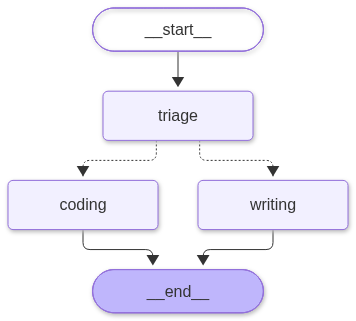

In [4]:
builder = StateGraph(HandOffState)
builder.add_node("triage", triage)
builder.add_node("coding", coding)
builder.add_node("writing", writing)
builder.add_edge(START,"triage")
builder.add_conditional_edges("triage", route_handoff, {"coding":"coding","writing":"writing"})
builder.add_edge("coding",END)
builder.add_edge("writing",END)
handoff_graph = builder.compile()
handoff_graph

In [5]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    print(handoff_graph.invoke({"request":q}))

{'request': '파이썬 for문 설명해줘', 'department': 'coding', 'answer': '[코딩담당]파이썬 for문 설명해줘 > 예제: for x in [1,2,3]: print(x)'}
{'request': '감사 인사말을 작성해줘', 'department': 'writing', 'answer': '[글쓰기 담당] 감사 인사말을 작성해줘 > 도입/본문/마무리로 구성하세요'}


In [6]:
for update in handoff_graph.stream({'request':'파이썬 리스트 예제'}, stream_mode="updates"):
    print(update)

{'triage': {'department': 'coding'}}
{'coding': {'answer': '[코딩담당]파이썬 리스트 예제 > 예제: for x in [1,2,3]: print(x)'}}


In [ ]:
llm = ChatOpenAI(model='gpt-5.6-luna', temperature=0)

# 1. 분류 에이전트
def triage(state: HandOffState) -> Command[Literal["coding","writing"]]:
    text = state["request"].lower()
    dept = 'coding' if any(k in text for k in ('파이썬','코드','python','for문')) else 'writing'
    # updates: 공유 상태(State)에 department 값을 저장. got: 다음에 실행할 노드를 지정
    return Command(update={'department':dept}, goto=dept) # Command로 다른 노드에 상태 전달

# 2. 코딩 에이전트
def coding(state: HandOffState):
    response = llm.invoke(
        f"당신은 파이썬 전문 강사입니다. 쉽게 설명하세요. \n질문: {state['request']}"
    )
    return {"answer": response.content}

# 3. 글쓰기 에이전트
def writing(state: HandOffState):
    response = llm.invoke(
        f"당신은 전문 작가입니다. 자연스럽게 글을 작성하세요.\n요청: {state['request']}"
    )
    return {"answer": response.content}

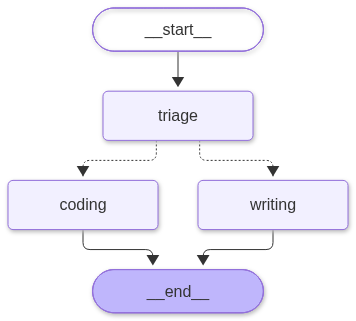

In [11]:
builder = StateGraph(HandOffState)
builder.add_node("triage",triage)
builder.add_node("coding",coding)
builder.add_node("writing",writing)
builder.add_edge(START, "triage")
builder.add_edge("coding",END)
builder.add_edge("writing",END)
graph = builder.compile()
graph

In [12]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    result = graph.invoke({"request":q})
    print(f'\n질문: {q}')
    print(f"담당: {result["department"]}")
    print(f"답변: {result["answer"]}")


질문: 파이썬 for문 설명해줘
담당: coding
답변: 파이썬의 `for`문은 **여러 개의 데이터를 하나씩 꺼내서 반복 처리할 때** 사용합니다.

## 1. 기본 형태

```python
for 변수 in 반복할_데이터:
    실행할_문장
```

예를 들어 리스트의 값을 하나씩 출력할 수 있습니다.

```python
fruits = ["사과", "바나나", "딸기"]

for fruit in fruits:
    print(fruit)
```

실행 결과:

```text
사과
바나나
딸기
```

동작 방식은 다음과 같습니다.

1. `fruits`에서 `"사과"`를 꺼냅니다.
2. `fruit` 변수에 저장합니다.
3. `print(fruit)`를 실행합니다.
4. 다음 값인 `"바나나"`, `"딸기"`도 같은 방식으로 처리합니다.

---

## 2. 숫자를 반복할 때: `range()`

`range()`는 일정한 범위의 숫자를 만들어 줍니다.

```python
for i in range(5):
    print(i)
```

결과:

```text
0
1
2
3
4
```

`range(5)`는 **0부터 5보다 작은 숫자까지**를 의미합니다.

### 1부터 5까지 출력하기

```python
for i in range(1, 6):
    print(i)
```

결과:

```text
1
2
3
4
5
```

형식은 다음과 같습니다.

```python
range(시작값, 끝값)
```

단, `끝값`은 포함되지 않습니다.

---

## 3. 반복하면서 계산하기

```python
for i in range(1, 6):
    print(i * 2)
```

결과:

```text
2
4
6
8
10
```

---

## 4. 문자열도 반복할 수 있습니다

문자열의 글자를 하나씩 꺼낼 수 있습니다.

```python
word = "Python"

for letter in word:
    print(letter)
```

결